# Transformasi Big Data HR Perusahaan Multinasional

**Judul:** Transformasi Big Data Sumber Daya Manusia Melalui Indeks Kesenjangan Gaji dan Agregasi Multi-Dimensi untuk Pemetaan Risiko Kehilangan Talenta

**Alur notebook:**
1. Konfigurasi & load data
2. Data cleaning
3. Feature engineering (data baru level individu)
4. Agregasi (data baru level cabang: *Global Branch Efficiency Matrix*)
5. Visualisasi rancangan (alur penelitian, before/after)
6. Visualisasi EDA (distribusi SDI, performa, status, boxplot, korelasi)
7. Empat grafik utama (A, B, C, D) + heatmap
8. Ringkasan temuan awal

> Semua gambar disimpan otomatis ke folder `figures/` (300 dpi) agar langsung bisa dimasukkan ke naskah proposal.

## 1. Konfigurasi & Import

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings("ignore")

# ============ KONFIGURASI (ubah sesuai kebutuhan) ============
KAGGLE_SLUG = "rohitgrewal/hr-data-mnc"            # dataset di Kaggle
CSV_PATH = os.environ.get("HR_CSV_PATH")           # isi path CSV manual untuk melewati download; None = download dari Kaggle
REF_YEAR = 2026                    # tahun acuan untuk Tenure_Years
SDI_THRESHOLD = 0.9                # ambang SDI untuk kategori underpaid
PERF_THRESHOLD = 4                 # ambang performa tinggi
ATTRITION_STATUS = ["Resigned", "Terminated"]   # status yang dihitung sebagai attrition
ACTIVE_STATUS = ["Active"]                      # status yang dihitung sebagai aktif
SAMPLE_N = 200_000                 # jumlah sampel untuk plot berat (boxplot, korelasi)
FIG_DIR = "figures"
OUT_DIR = "output"
RANDOM_STATE = 42
# ==============================================================

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelsize": 11})

def save_fig(name):
    path = os.path.join(FIG_DIR, name + ".png")
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    print("Tersimpan:", path)

## 1b. Download Dataset dari Kaggle
Sel ini mengunduh dataset `rohitgrewal/hr-data-mnc` memakai pustaka `kagglehub` (file di-cache, jadi pengunduhan kedua kali langsung cepat).

**Jika muncul error autentikasi**, siapkan salah satu cara berikut lalu jalankan ulang sel:
- Buat API token di Kaggle (*Settings > API > Create New Token*), lalu simpan file `kaggle.json` di `~/.kaggle/` (Windows: `C:\Users\<nama>\.kaggle\`), atau
- Set variabel lingkungan `KAGGLE_USERNAME` dan `KAGGLE_KEY`, atau
- Jalankan `kagglehub.login()` dan masukkan username serta token saat diminta, atau
- Unduh manual dari halaman dataset, lalu isi `CSV_PATH` di sel konfigurasi dengan lokasi file CSV.

In [2]:
import glob
import subprocess
import sys

def ensure(pkg):
    try:
        __import__(pkg)
    except ImportError:
        print(f"Memasang {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

if CSV_PATH is None:
    ensure("kagglehub")
    import kagglehub
    try:
        data_dir = kagglehub.dataset_download(KAGGLE_SLUG)
    except Exception as e:
        print("Download gagal:", type(e).__name__, e)
        print("Mencoba login interaktif ke Kaggle ...")
        kagglehub.login()
        data_dir = kagglehub.dataset_download(KAGGLE_SLUG)

    csv_files = sorted(glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True))
    if not csv_files:
        raise FileNotFoundError(f"Tidak ada file CSV di {data_dir}")
    CSV_PATH = max(csv_files, key=os.path.getsize)   # ambil CSV terbesar = dataset utama
    print("Folder dataset :", data_dir)
    print("File CSV       :", CSV_PATH)
else:
    print("Memakai CSV lokal:", CSV_PATH)

print(f"Ukuran file    : {os.path.getsize(CSV_PATH) / 1024**2:,.1f} MB")

100%|██████████| 66.7M/66.7M [00:00<00:00, 206MB/s]

Extracting files...


Folder dataset : /root/.cache/kagglehub/datasets/rohitgrewal/hr-data-mnc/versions/1
File CSV       : /root/.cache/kagglehub/datasets/rohitgrewal/hr-data-mnc/versions/1/HR_Data_MNC_Data Science Lovers.csv
Ukuran file    : 233.6 MB


## 2. Load Data 

In [3]:
# Kolom teks dengan nilai berulang dibaca sebagai 'category' agar memori jauh lebih kecil.
# Full_Name tidak dibutuhkan untuk analisis (sekaligus menghindari data pribadi), jadi dilewati.
header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print("Kolom pada file:", header)

wanted = ["Employee_ID", "Department", "Job_Title", "Hire_Date", "Location",
          "Performance_Rating", "Experience_Years", "Status", "Work_Mode", "Salary_INR"]
missing_cols = [c for c in wanted if c not in header]
if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan di CSV: {missing_cols}. Sesuaikan daftar 'wanted'.")

dtype_map = {"Department": "category", "Job_Title": "category", "Location": "category",
             "Status": "category", "Work_Mode": "category"}

df = pd.read_csv(CSV_PATH, usecols=wanted, dtype=dtype_map)
print(f"Dimensi data awal: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Memori: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
df.head()

Kolom pada file: ['Unnamed: 0', 'Employee_ID', 'Full_Name', 'Department', 'Job_Title', 'Hire_Date', 'Location', 'Performance_Rating', 'Experience_Years', 'Status', 'Work_Mode', 'Salary_INR']
Dimensi data awal: 2,000,000 baris x 10 kolom
Memori: 430.6 MB


,Employee_ID,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686
2,EMP0000003,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2,Active,On-site,1430084
3,EMP0000004,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1,Active,On-site,990689
4,EMP0000005,Operations,Logistics Coordinator,2024-12-09,"Lake Kimberly, Palestinian Territory",5,0,Active,On-site,535082


In [4]:
df_raw_shape = df.shape                      # simpan untuk visual before/after
print("Nilai unik Status    :", df["Status"].value_counts(dropna=False).to_dict())
print("Nilai unik Work_Mode :", df["Work_Mode"].value_counts(dropna=False).to_dict())
print("Jumlah Department    :", df["Department"].nunique())
print("Contoh Location      :", df["Location"].dropna().unique()[:5].tolist())

Nilai unik Status    : {'Active': 1401558, 'Resigned': 398660, 'Retired': 99912, 'Terminated': 99870}
Nilai unik Work_Mode : {'On-site': 1199109, 'Remote': 800891}
Jumlah Department    : 7
Contoh Location      : ['Isaacland, Denmark', 'Anthonyside, Costa Rica', 'Port Christinaport, Saudi Arabia', 'Port Shelbychester, Antigua and Barbuda', 'Lake Kimberly, Palestinian Territory']


## 3. Data Cleaning

In [5]:
clean_log = {}
clean_log["baris_awal"] = len(df)

# 1) Duplikat berdasarkan Employee_ID
dup = df.duplicated(subset="Employee_ID").sum()
df = df.drop_duplicates(subset="Employee_ID")
clean_log["duplikat_dibuang"] = int(dup)

# 2) Konversi tipe data
df["Hire_Date"] = pd.to_datetime(df["Hire_Date"], errors="coerce")
for c in ["Performance_Rating", "Experience_Years", "Salary_INR"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3) Missing value pada kolom kunci
key_cols = ["Department", "Job_Title", "Hire_Date", "Location", "Performance_Rating",
            "Experience_Years", "Status", "Work_Mode", "Salary_INR"]
print("Missing value per kolom:")
print(df[key_cols].isna().sum()[lambda s: s > 0].to_string() or "Tidak ada missing value")
before = len(df)
df = df.dropna(subset=key_cols)
clean_log["missing_dibuang"] = before - len(df)

# 4) Nilai tidak valid (gaji <= 0, pengalaman negatif)
before = len(df)
df = df[(df["Salary_INR"] > 0) & (df["Experience_Years"] >= 0)]
clean_log["tidak_valid_dibuang"] = before - len(df)

# 5) Hire_Date di masa depan terhadap tahun acuan
before = len(df)
df = df[df["Hire_Date"].dt.year <= REF_YEAR]
clean_log["hire_date_melebihi_tahun_acuan"] = before - len(df)

# 6) Rapikan kategori yang tidak terpakai setelah filter
for c in df.select_dtypes("category").columns:
    df[c] = df[c].cat.remove_unused_categories()

clean_log["baris_akhir"] = len(df)
pd.Series(clean_log, name="jumlah").to_frame()

Missing value per kolom:
Series([], )


,jumlah
baris_awal,2000000
duplikat_dibuang,0
missing_dibuang,0
tidak_valid_dibuang,0
hire_date_melebihi_tahun_acuan,0
baris_akhir,2000000


In [6]:
# Outlier gaji: hanya dilaporkan (tidak dibuang) memakai aturan IQR agar transparan di naskah.
q1, q3 = df["Salary_INR"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((df["Salary_INR"] < low) | (df["Salary_INR"] > high)).sum()
print(f"Batas IQR gaji: {low:,.0f} s.d. {high:,.0f} INR")
print(f"Jumlah outlier gaji: {n_out:,} ({n_out / len(df) * 100:.2f}%)")
df["Salary_INR"].describe().round(2).to_frame().T

Batas IQR gaji: -69,753 s.d. 1,759,844 INR
Jumlah outlier gaji: 69,298 (3.46%)


,count,mean,std,min,25%,50%,75%,max
Salary_INR,2000000.0,896887.76,402610.3,300000.0,616346.0,811026.5,1073745.25,2999976.0


## 4. Feature Engineering (Data Baru Level Mikro)

In [8]:
# --- 4.1 Ekstraksi geografis: City & Country dari Location ---
loc = df["Location"].astype(str)
if loc.str.contains(",").mean() > 0.5:
    parts = loc.str.rsplit(",", n=1, expand=True)
    df["City"] = parts[0].str.strip().astype("category")
    df["Country"] = parts[1].str.strip().astype("category")
else:
    print("PERINGATAN: Location tidak berformat 'Kota, Negara'. City dan Country diisi sama dengan Location.")
    df["City"] = df["Location"]
    df["Country"] = df["Location"]

# --- 4.2 Masa kerja ---
df["Tenure_Years"] = REF_YEAR - df["Hire_Date"].dt.year

# --- 4.3 Salary Disparity Index (SDI) ---
mean_sal = df.groupby(["Department", "Job_Title"], observed=True)["Salary_INR"].transform("mean")
df["Salary_Disparity_Index"] = df["Salary_INR"] / mean_sal

# --- 4.4 Performance to Experience Ratio ---
df["Performance_to_Exp_Ratio"] = df["Performance_Rating"] / (df["Experience_Years" ] + 1)

# --- 4.5 Flag attrition / aktif ---
df["Is_Attrition"] = df["Status"].isin(ATTRITION_STATUS).astype("int8")
df["Is_Active"] = df["Status"].isin(ACTIVE_STATUS)

# --- 4.6 Talent Segment (definisi lengkap, tanpa celah) ---
conds = [
    (df["Is_Attrition"] == 1) & (df["Performance_Rating"] >= PERF_THRESHOLD),
    df["Is_Active"] & (df["Performance_Rating"] >= PERF_THRESHOLD) & (df["Salary_Disparity_Index"] < SDI_THRESHOLD),
    df["Is_Active"] & (df["Performance_Rating"] >= PERF_THRESHOLD) & (df["Salary_Disparity_Index"] >= SDI_THRESHOLD),
]
labels = ["Lost Star Talent", "High Flight Risk (Underpaid Star)", "Stable Workforce"]
df["Talent_Segment"] = pd.Categorical(np.select(conds, labels, default="Standard / Low Perf"),
                                      categories=labels + ["Standard / Low Perf"])

print("Rentang SDI:", round(df["Salary_Disparity_Index"].min(), 3), "-", round(df["Salary_Disparity_Index"].max(), 3))
print(df["Talent_Segment"].value_counts().to_string())
df[["Employee_ID", "Department", "Job_Title", "Country", "Tenure_Years",
    "Salary_Disparity_Index", "Performance_to_Exp_Ratio", "Talent_Segment"]].head()

Rentang SDI: 0.498 - 1.509
Talent_Segment
Standard / Low Perf                  1239540
Stable Workforce                      342403
High Flight Risk (Underpaid Star)     218778
Lost Star Talent                      199279


,Employee_ID,Department,Job_Title,Country,Tenure_Years,Salary_Disparity_Index,Performance_to_Exp_Ratio,Talent_Segment
0,EMP0000001,IT,Software Engineer,Denmark,15,1.321950,0.333333,Lost Star Talent
1,EMP0000002,Marketing,SEO Specialist,Costa Rica,8,1.210191,0.250000,Standard / Low Perf
2,EMP0000003,HR,HR Manager,Saudi Arabia,3,1.141873,0.333333,Standard / Low Perf
3,EMP0000004,IT,Software Engineer,Antigua and Barbuda,3,0.826083,0.500000,Standard / Low Perf
4,EMP0000005,Operations,Logistics Coordinator,Palestinian Territory,2,0.823670,5.000000,High Flight Risk (Underpaid Star)


## 5. Agregasi (Data Baru Level Makro): *Global Branch Efficiency Matrix*

In [9]:
branch = (df.groupby(["Country", "Department", "Work_Mode"], observed=True)
            .agg(Total_Employees=("Employee_ID", "count"),
                 Attrition_Count=("Is_Attrition", "sum"),
                 Avg_Salary_Disparity=("Salary_Disparity_Index", "mean"),
                 Avg_Performance=("Performance_Rating", "mean"))
            .reset_index())
branch["Turnover_Rate_Pct"] = branch["Attrition_Count"] / branch["Total_Employees"] * 100
branch = branch[["Country", "Department", "Work_Mode", "Total_Employees", "Attrition_Count",
                 "Turnover_Rate_Pct", "Avg_Salary_Disparity", "Avg_Performance"]]
branch = branch.round({"Turnover_Rate_Pct": 3, "Avg_Salary_Disparity": 4, "Avg_Performance": 3})

branch.to_csv(os.path.join(OUT_DIR, "new_dataset_branch_efficiency.csv"), index=False)
print(f"Dataset agregat baru: {branch.shape[0]:,} baris x {branch.shape[1]} kolom -> {OUT_DIR}/new_dataset_branch_efficiency.csv")
branch.head(10)

Dataset agregat baru: 3,402 baris x 8 kolom -> output/new_dataset_branch_efficiency.csv


,Country,Department,Work_Mode,Total_Employees,Attrition_Count,Turnover_Rate_Pct,Avg_Salary_Disparity,Avg_Performance
0,Afghanistan,Finance,On-site,476,111,23.319,1.0046,3.006
1,Afghanistan,Finance,Remote,312,76,24.359,1.0024,2.894
2,Afghanistan,HR,On-site,384,91,23.698,0.9830,3.141
3,Afghanistan,HR,Remote,267,70,26.217,0.9956,2.914
4,Afghanistan,IT,On-site,1537,401,26.090,1.0025,2.992
5,Afghanistan,IT,Remote,912,232,25.439,0.9959,3.047
6,Afghanistan,Marketing,On-site,567,140,24.691,0.9963,2.822
7,Afghanistan,Marketing,Remote,371,85,22.911,1.0203,2.892
8,Afghanistan,Operations,On-site,722,181,25.069,0.9974,2.918
9,Afghanistan,Operations,Remote,493,115,23.327,0.9875,2.913


In [10]:
# Opsional: simpan dataset individu hasil feature engineering (Parquet jauh lebih ringan dari CSV).
try:
    cols_out = ["Employee_ID", "Department", "Job_Title", "Country", "City", "Work_Mode", "Status",
                "Performance_Rating", "Experience_Years", "Tenure_Years", "Salary_INR",
                "Salary_Disparity_Index", "Performance_to_Exp_Ratio", "Talent_Segment"]
    df[cols_out].to_parquet(os.path.join(OUT_DIR, "hr_features.parquet"), index=False)
    print("Tersimpan:", os.path.join(OUT_DIR, "hr_features.parquet"))
except Exception as e:
    print("Parquet dilewati (install pyarrow bila perlu):", e)

Tersimpan: output/hr_features.parquet


## 6. Visualisasi Rancangan Penelitian

### Gambar 1. Diagram Alur Penelitian

Tersimpan: figures/fig01_alur_penelitian.png


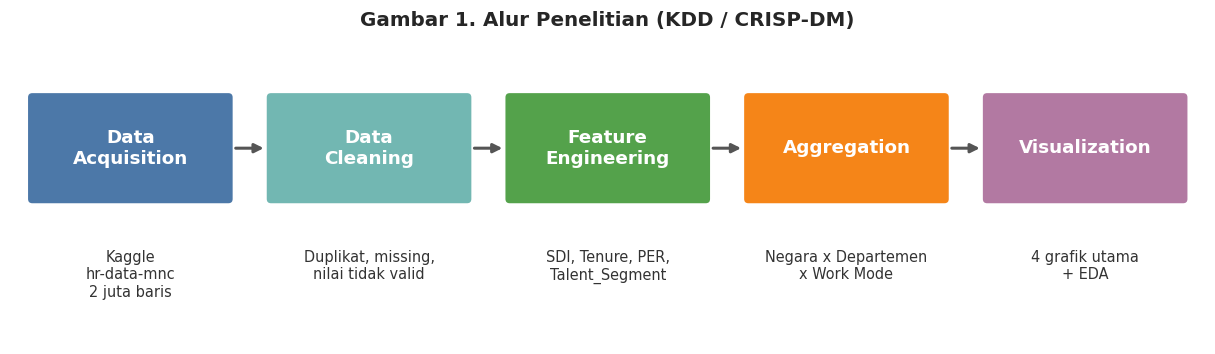

In [11]:
steps = [("Data\nAcquisition", "Kaggle\nhr-data-mnc\n2 juta baris"),
         ("Data\nCleaning", "Duplikat, missing,\nnilai tidak valid"),
         ("Feature\nEngineering", "SDI, Tenure, PER,\nTalent_Segment"),
         ("Aggregation", "Negara x Departemen\nx Work Mode"),
         ("Visualization", "4 grafik utama\n+ EDA")]
colors = ["#4C78A8", "#72B7B2", "#54A24B", "#F58518", "#B279A2"]

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.set_xlim(0, 14); ax.set_ylim(0, 3.6); ax.axis("off")
w, h, gap = 2.3, 1.2, 0.5
for i, ((title, sub), col) in enumerate(zip(steps, colors)):
    x = 0.25 + i * (w + gap)
    ax.add_patch(mpatches.FancyBboxPatch((x, 1.7), w, h, boxstyle="round,pad=0.05", fc=col, ec="none"))
    ax.text(x + w / 2, 1.7 + h / 2, title, ha="center", va="center", color="white", fontsize=12, fontweight="bold")
    ax.text(x + w / 2, 1.1, sub, ha="center", va="top", fontsize=9.5, color="#333")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + w + gap - 0.05, 2.3), xytext=(x + w + 0.05, 2.3),
                    arrowprops=dict(arrowstyle="-|>", lw=2, color="#555"))
ax.set_title("Gambar 1. Alur Penelitian (KDD / CRISP-DM)", pad=8)
save_fig("fig01_alur_penelitian")
plt.show()

### Gambar 2. Skema Transformasi Data (Sebelum vs Sesudah)

Tersimpan: figures/fig02_skema_before_after.png


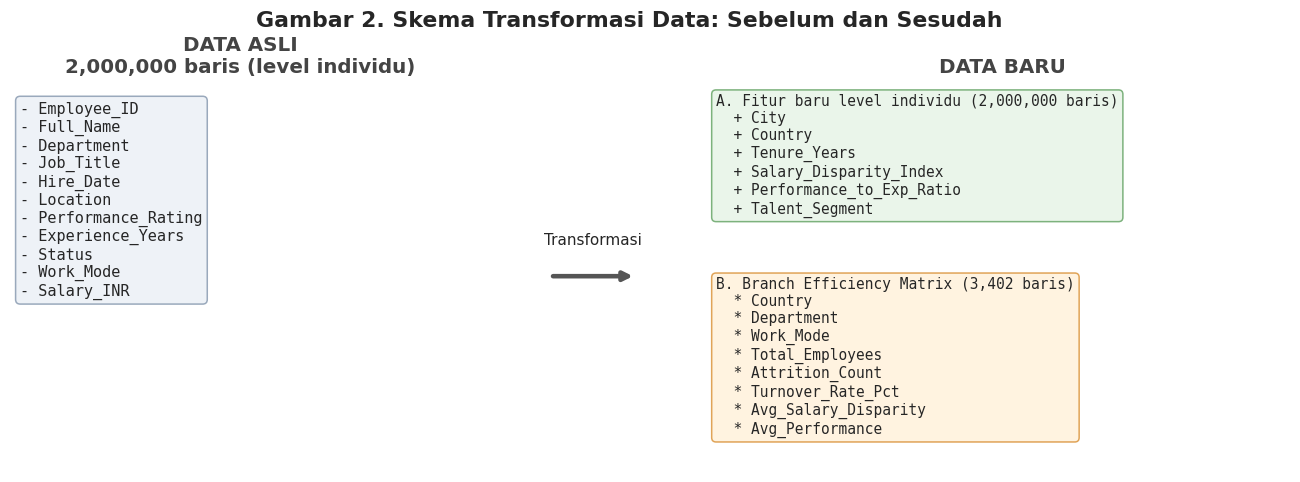

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.2, 0.25, 1.5]})

# Panel kiri: data asli
ax = axes[0]; ax.axis("off")
orig_cols = ["Employee_ID", "Full_Name", "Department", "Job_Title", "Hire_Date", "Location",
             "Performance_Rating", "Experience_Years", "Status", "Work_Mode", "Salary_INR"]
ax.set_title(f"DATA ASLI\n{df_raw_shape[0]:,} baris (level individu)", color="#444")
ax.text(0.02, 0.95, "\n".join("- " + c for c in orig_cols), va="top", fontsize=10, family="monospace",
        bbox=dict(boxstyle="round", fc="#EEF2F7", ec="#9AA9BC"))

# Panah
axes[1].axis("off")
axes[1].annotate("", xy=(0.95, 0.5), xytext=(0.05, 0.5), arrowprops=dict(arrowstyle="-|>", lw=3, color="#555"))
axes[1].text(0.5, 0.58, "Transformasi", ha="center", fontsize=10)

# Panel kanan: data baru
ax = axes[2]; ax.axis("off")
ax.set_title("DATA BARU", color="#444")
mikro = ["City", "Country", "Tenure_Years", "Salary_Disparity_Index", "Performance_to_Exp_Ratio", "Talent_Segment"]
makro = ["Country", "Department", "Work_Mode", "Total_Employees", "Attrition_Count",
         "Turnover_Rate_Pct", "Avg_Salary_Disparity", "Avg_Performance"]
ax.text(0.0, 0.97, f"A. Fitur baru level individu ({len(df):,} baris)\n" + "\n".join("  + " + c for c in mikro),
        va="top", fontsize=9.5, family="monospace", bbox=dict(boxstyle="round", fc="#EAF5EA", ec="#7DB27D"))
ax.text(0.0, 0.50, f"B. Branch Efficiency Matrix ({len(branch):,} baris)\n" + "\n".join("  * " + c for c in makro),
        va="top", fontsize=9.5, family="monospace", bbox=dict(boxstyle="round", fc="#FFF3E0", ec="#E0A458"))
fig.suptitle("Gambar 2. Skema Transformasi Data: Sebelum dan Sesudah", fontweight="bold", y=1.02)
save_fig("fig02_skema_before_after")
plt.show()

## 7. Eksplorasi Data Awal (EDA)

### Gambar 3. Distribusi Salary Disparity Index (SDI)
Garis putus-putus merah pada 0,9 adalah ambang *underpaid* yang dipakai untuk segmen *High Flight Risk*. Histogram ini menjadi justifikasi empiris pemilihan ambang tersebut.

Tersimpan: figures/fig03_distribusi_sdi.png


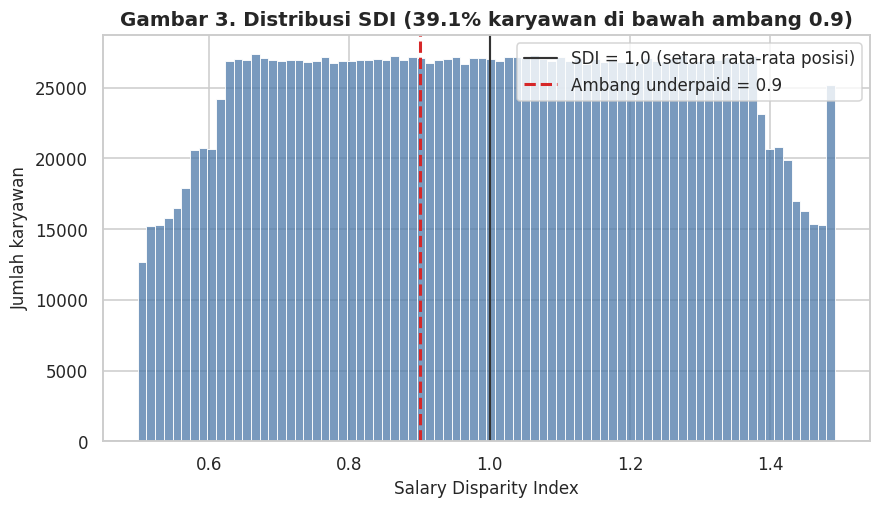

In [13]:
sdi = df["Salary_Disparity_Index"]
pct_under = (sdi < SDI_THRESHOLD).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(sdi.clip(upper=sdi.quantile(0.995)), bins=80, color="#4C78A8", edgecolor="white", ax=ax)
ax.axvline(1.0, color="#333", ls="-", lw=1.4, label="SDI = 1,0 (setara rata-rata posisi)")
ax.axvline(SDI_THRESHOLD, color="#D62728", ls="--", lw=2, label=f"Ambang underpaid = {SDI_THRESHOLD}")
ax.set_xlabel("Salary Disparity Index"); ax.set_ylabel("Jumlah karyawan")
ax.set_title(f"Gambar 3. Distribusi SDI ({pct_under:.1f}% karyawan di bawah ambang {SDI_THRESHOLD})")
ax.legend()
save_fig("fig03_distribusi_sdi")
plt.show()

### Gambar 4. Distribusi Performance Rating dan Status Kepegawaian
Memastikan data cukup seimbang, terutama jumlah karyawan berkinerja tinggi dan yang keluar, karena menentukan ukuran segmen *Lost Star Talent*.

Tersimpan: figures/fig04_distribusi_performa_status.png


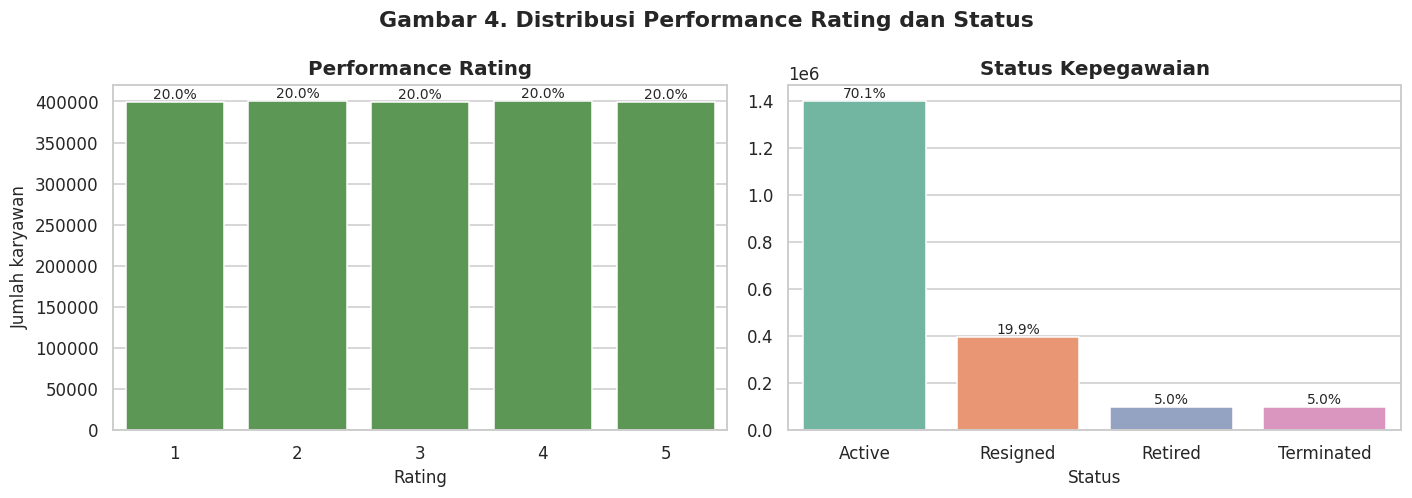

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

perf = df["Performance_Rating"].round().astype(int).value_counts().sort_index()
sns.barplot(x=perf.index.astype(str), y=perf.values, color="#54A24B", ax=axes[0])
for i, v in enumerate(perf.values):
    axes[0].text(i, v, f"{v / perf.sum() * 100:.1f}%", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Performance Rating"); axes[0].set_xlabel("Rating"); axes[0].set_ylabel("Jumlah karyawan")

st = df["Status"].value_counts()
sns.barplot(x=st.index.astype(str), y=st.values, palette="Set2", ax=axes[1])
for i, v in enumerate(st.values):
    axes[1].text(i, v, f"{v / st.sum() * 100:.1f}%", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Status Kepegawaian"); axes[1].set_xlabel("Status"); axes[1].set_ylabel("")

fig.suptitle("Gambar 4. Distribusi Performance Rating dan Status", fontweight="bold")
plt.tight_layout()
save_fig("fig04_distribusi_performa_status")
plt.show()

### Gambar 5. Boxplot SDI berdasarkan Status
Visual kunci untuk hipotesis: apakah karyawan yang keluar cenderung digaji lebih rendah dari rata-rata posisinya?

Tersimpan: figures/fig05_boxplot_sdi_status.png


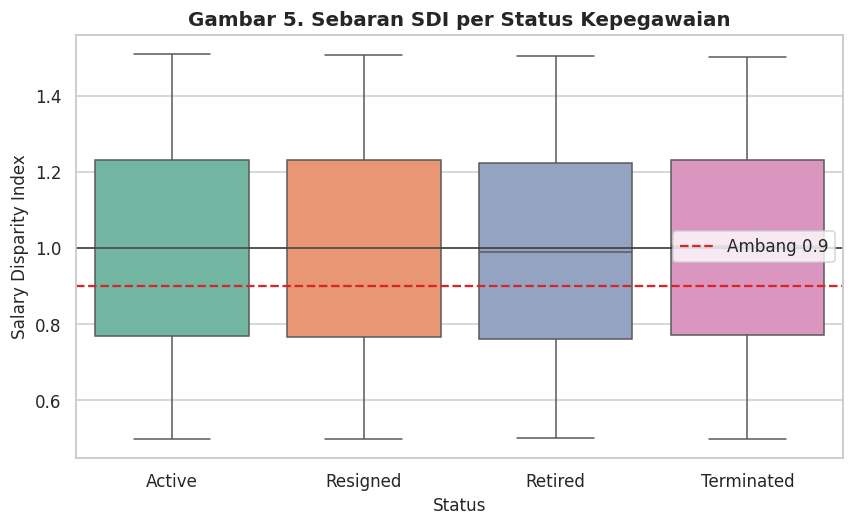

Median SDI per status (seluruh data):
Status
Active        1.000
Resigned      1.000
Retired       0.998
Terminated    0.999


In [15]:
samp = df.sample(n=min(SAMPLE_N, len(df)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=samp, x="Status", y="Salary_Disparity_Index", palette="Set2", showfliers=False, ax=ax)
ax.axhline(1.0, color="#333", lw=1, ls="-")
ax.axhline(SDI_THRESHOLD, color="#D62728", lw=1.5, ls="--", label=f"Ambang {SDI_THRESHOLD}")
med = df.groupby("Status", observed=True)["Salary_Disparity_Index"].median().round(3)
ax.set_title("Gambar 5. Sebaran SDI per Status Kepegawaian")
ax.set_ylabel("Salary Disparity Index"); ax.legend()
save_fig("fig05_boxplot_sdi_status")
plt.show()
print("Median SDI per status (seluruh data):")
print(med.to_string())

## 8. Empat Grafik Utama

### Grafik A. Turnover Rate per Departemen dan Work Mode

Tersimpan: figures/grafikA_turnover_dept_workmode.png


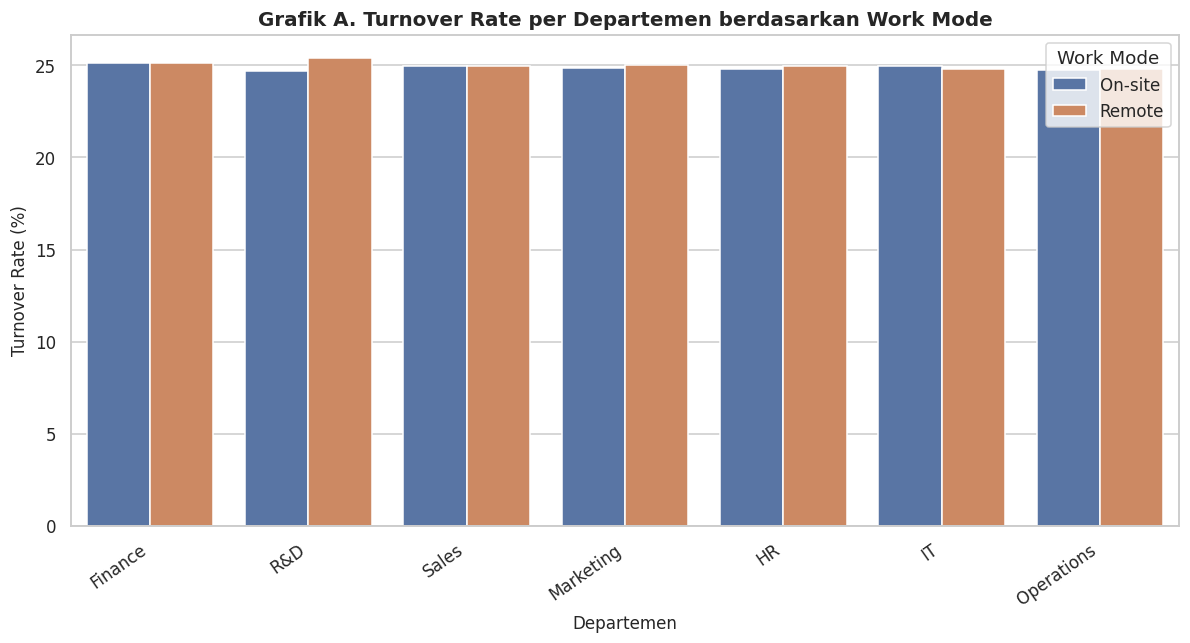

Work_Mode,On-site,Remote
Department,,
Finance,25.14,25.12
HR,24.81,24.99
IT,24.97,24.83
Marketing,24.87,25.00
Operations,24.74,24.78
R&D,24.69,25.40
Sales,24.99,24.97


In [16]:
# Dihitung dari total (bukan rata-rata dari rata-rata) agar tertimbang dengan benar.
ga = (branch.groupby(["Department", "Work_Mode"], observed=True)[["Attrition_Count", "Total_Employees"]].sum()
            .assign(Turnover_Rate_Pct=lambda d: d["Attrition_Count"] / d["Total_Employees"] * 100)
            .reset_index())
order = ga.groupby("Department")["Turnover_Rate_Pct"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(13, 5.8))
sns.barplot(data=ga, x="Department", y="Turnover_Rate_Pct", hue="Work_Mode", order=order, palette="deep", ax=ax)
ax.set_xlabel("Departemen"); ax.set_ylabel("Turnover Rate (%)")
ax.set_title("Grafik A. Turnover Rate per Departemen berdasarkan Work Mode")
plt.xticks(rotation=35, ha="right")
ax.legend(title="Work Mode")
save_fig("grafikA_turnover_dept_workmode")
plt.show()

# Ringkasan numerik untuk narasi di naskah
ga.pivot(index="Department", columns="Work_Mode", values="Turnover_Rate_Pct").round(2)

### Grafik B. Proporsi Segmen Risiko Talenta

Tersimpan: figures/grafikB_segmen_talenta.png


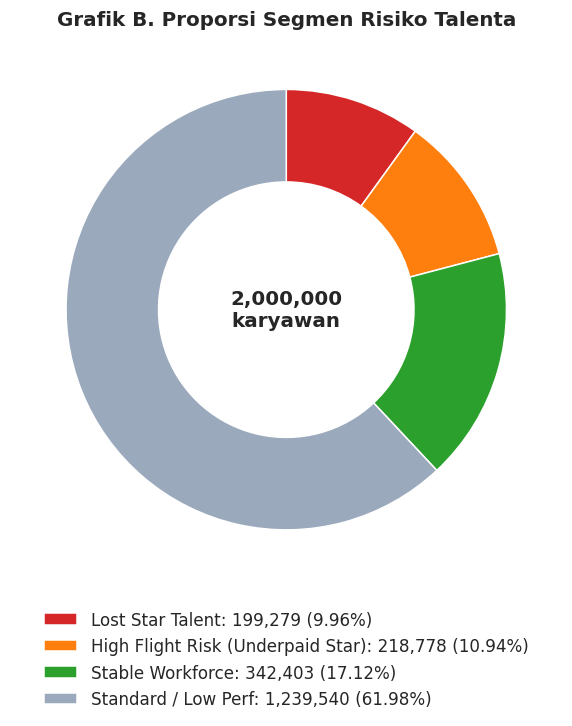

In [17]:
seg = df["Talent_Segment"].value_counts().reindex(df["Talent_Segment"].cat.categories)
seg_colors = ["#D62728", "#FF7F0E", "#2CA02C", "#9AA9BC"]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
wedges, _ = ax.pie(seg.values, colors=seg_colors, startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.42, edgecolor="white"))
ax.text(0, 0, f"{seg.sum():,}\nkaryawan", ha="center", va="center", fontsize=13, fontweight="bold")
# Legenda berisi persentase agar segmen kecil tetap terbaca
ax.legend(wedges, [f"{k}: {v:,} ({v / seg.sum() * 100:.2f}%)" for k, v in seg.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=1, frameon=False)
ax.set_title("Grafik B. Proporsi Segmen Risiko Talenta")
save_fig("grafikB_segmen_talenta")
plt.show()

### Grafik C. Kurva Pengalaman Kerja vs Kompensasi berdasarkan Status
Pengalaman dikelompokkan ke dalam rentang agar garis lebih halus. Panel kiri memakai rata-rata gaji, panel kanan memakai rata-rata SDI (gaji yang sudah dinormalisasi per posisi).

Tersimpan: figures/grafikC_pengalaman_kompensasi.png


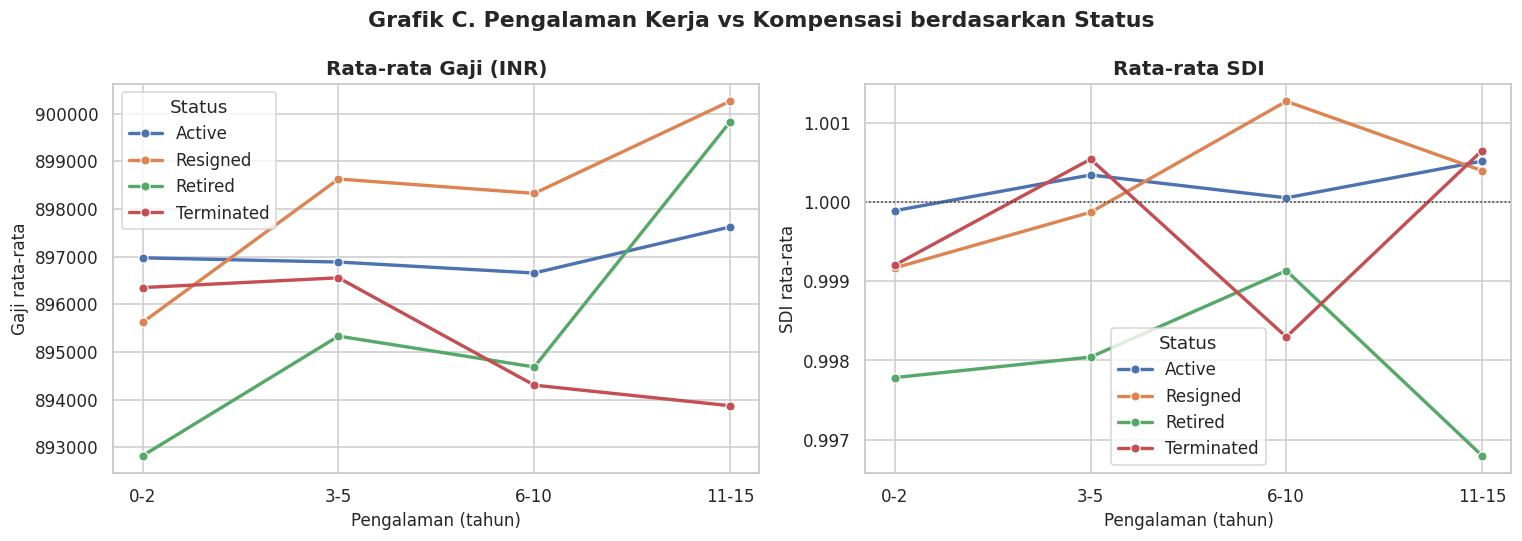

In [18]:
bins = [-0.01, 2, 5, 10, 15, 20, 100]
labels_exp = ["0-2", "3-5", "6-10", "11-15", "16-20", ">20"]
tmp = df[["Experience_Years", "Status", "Salary_INR", "Salary_Disparity_Index"]].copy()
tmp["Exp_Group"] = pd.cut(tmp["Experience_Years"], bins=bins, labels=labels_exp)
gc = (tmp.groupby(["Exp_Group", "Status"], observed=True)
         .agg(Avg_Salary=("Salary_INR", "mean"), Avg_SDI=("Salary_Disparity_Index", "mean"))
         .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=gc, x="Exp_Group", y="Avg_Salary", hue="Status", marker="o", lw=2.2, ax=axes[0])
axes[0].set_title("Rata-rata Gaji (INR)"); axes[0].set_xlabel("Pengalaman (tahun)"); axes[0].set_ylabel("Gaji rata-rata")
sns.lineplot(data=gc, x="Exp_Group", y="Avg_SDI", hue="Status", marker="o", lw=2.2, ax=axes[1])
axes[1].axhline(1.0, color="#333", lw=1, ls=":")
axes[1].set_title("Rata-rata SDI"); axes[1].set_xlabel("Pengalaman (tahun)"); axes[1].set_ylabel("SDI rata-rata")
fig.suptitle("Grafik C. Pengalaman Kerja vs Kompensasi berdasarkan Status", fontweight="bold")
plt.tight_layout()
save_fig("grafikC_pengalaman_kompensasi")
plt.show()

### Grafik D. Top 10 Negara dengan Turnover Tertinggi

Tersimpan: figures/grafikD_top10_negara_turnover.png


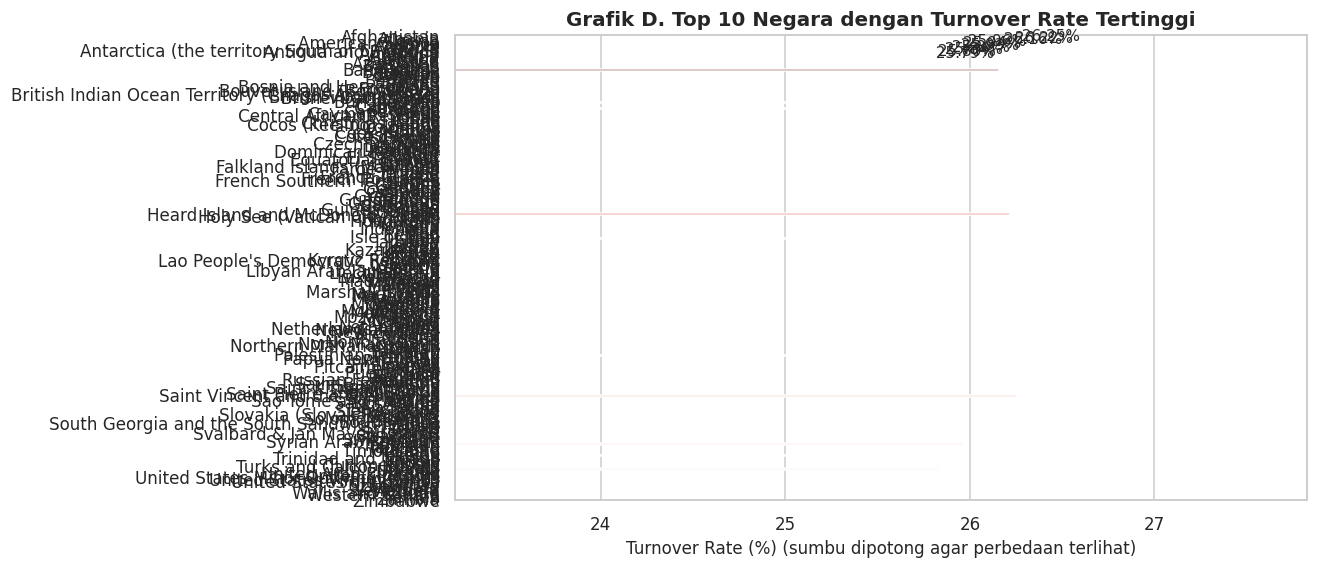

,Country,Attrition_Count,Total_Employees,Turnover_Rate_Pct
0,Samoa,2164,8243,26.252578
1,Heard Island and McDonald Islands,2107,8037,26.216250
2,Barbados,2114,8081,26.160129
3,Tajikistan,2120,8166,25.961303
4,Canada,2115,8155,25.935009
5,Panama,2128,8208,25.925926
6,Tonga,2132,8239,25.876927
7,Uganda,2108,8158,25.839667
8,Italy,2145,8314,25.799856
9,Burundi,2129,8256,25.787306


In [19]:
gd = (branch.groupby("Country", observed=True)[["Attrition_Count", "Total_Employees"]].sum()
            .assign(Turnover_Rate_Pct=lambda d: d["Attrition_Count"] / d["Total_Employees"] * 100)
            .sort_values("Turnover_Rate_Pct", ascending=False).head(10).reset_index())

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=gd, y="Country", x="Turnover_Rate_Pct", palette="Reds_r", ax=ax)
for i, v in enumerate(gd["Turnover_Rate_Pct"]):
    ax.text(v, i, f" {v:.2f}%", va="center", fontsize=10)
lo = max(0, gd["Turnover_Rate_Pct"].min() * 0.9)
ax.set_xlim(lo, gd["Turnover_Rate_Pct"].max() * 1.06)
ax.set_xlabel("Turnover Rate (%) (sumbu dipotong agar perbedaan terlihat)"); ax.set_ylabel("")
ax.set_title("Grafik D. Top 10 Negara dengan Turnover Rate Tertinggi")
save_fig("grafikD_top10_negara_turnover")
plt.show()
gd

## 9. Visualisasi Tambahan (Opsional, Bernilai Tinggi)

### Gambar 6. Heatmap Turnover Rate Negara x Departemen

Tersimpan: figures/fig06_heatmap_negara_departemen.png


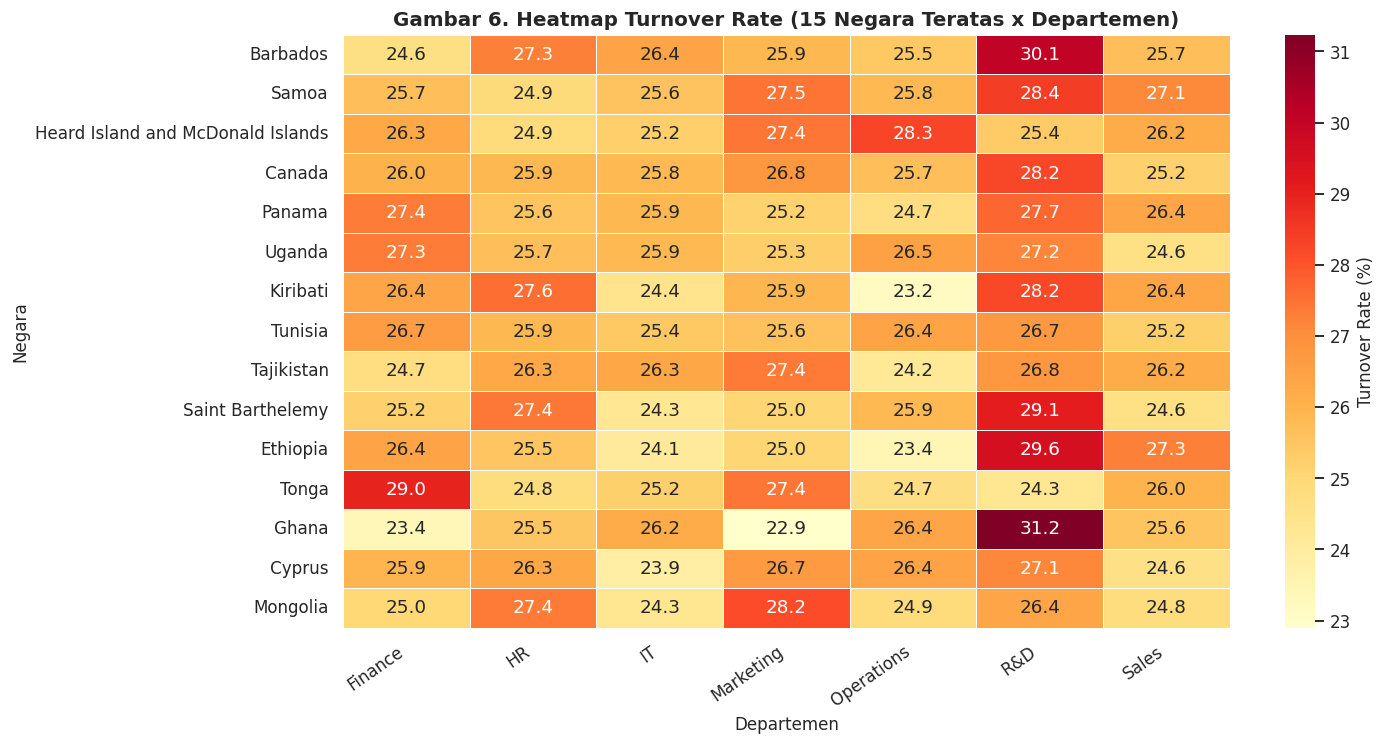

In [20]:
hm = (branch.groupby(["Country", "Department"], observed=True)[["Attrition_Count", "Total_Employees"]].sum()
            .assign(rate=lambda d: d["Attrition_Count"] / d["Total_Employees"] * 100)["rate"]
            .unstack("Department"))
top_c = hm.mean(axis=1).sort_values(ascending=False).head(15).index   # 15 negara teratas agar terbaca
hm = hm.loc[top_c]

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(hm, cmap="YlOrRd", annot=hm.shape[1] <= 12, fmt=".1f", linewidths=0.4,
            cbar_kws={"label": "Turnover Rate (%)"}, ax=ax)
ax.set_title("Gambar 6. Heatmap Turnover Rate (15 Negara Teratas x Departemen)")
ax.set_xlabel("Departemen"); ax.set_ylabel("Negara")
plt.xticks(rotation=35, ha="right")
save_fig("fig06_heatmap_negara_departemen")
plt.show()

### Gambar 7. Heatmap Korelasi Variabel Numerik

Tersimpan: figures/fig07_heatmap_korelasi.png


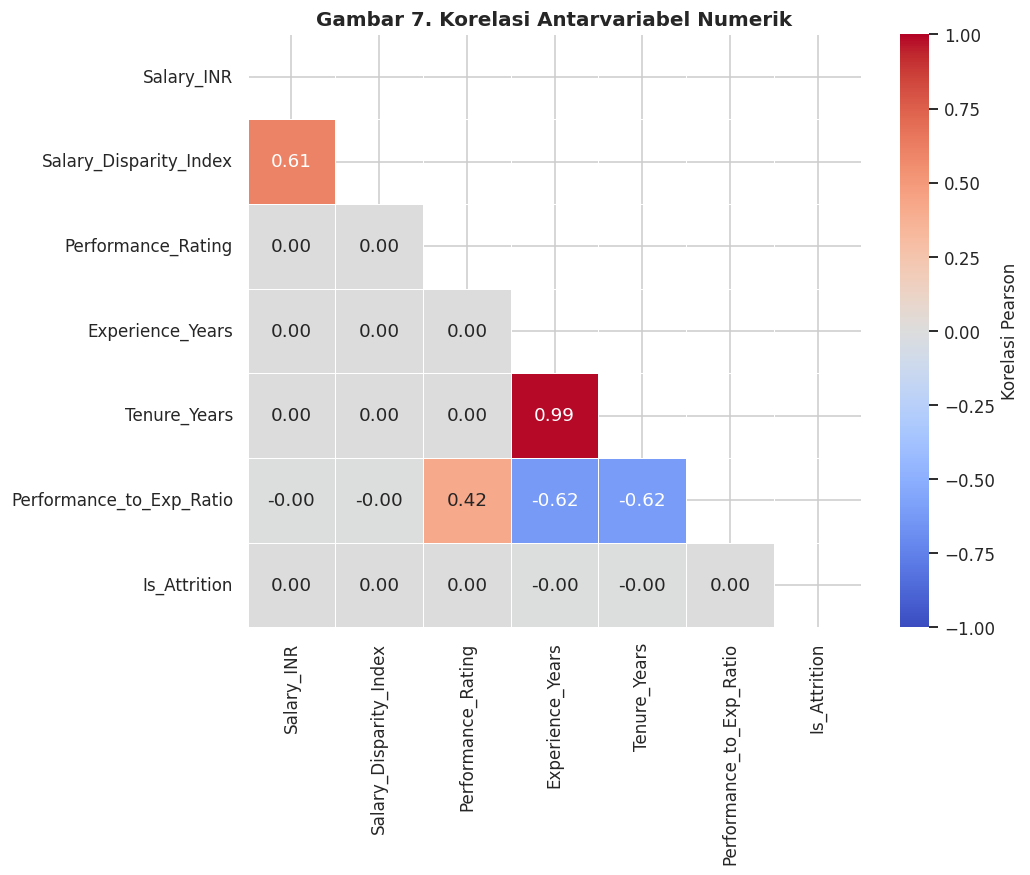

In [21]:
num_cols = ["Salary_INR", "Salary_Disparity_Index", "Performance_Rating", "Experience_Years",
            "Tenure_Years", "Performance_to_Exp_Ratio", "Is_Attrition"]
corr = samp[num_cols].astype(float).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Gambar 7. Korelasi Antarvariabel Numerik")
save_fig("fig07_heatmap_korelasi")
plt.show()

## 10. Ringkasan Temuan Awal (otomatis)
Sel ini menghasilkan angka-angka kunci yang bisa langsung dikutip pada bagian *Analisis Grafik & Temuan Awal* (Bab III, subbab 3.3). Tuliskan sebagai **indikasi awal**, bukan kesimpulan final.

In [22]:
overall = df["Is_Attrition"].mean() * 100
wm = (branch.groupby("Work_Mode", observed=True)[["Attrition_Count", "Total_Employees"]].sum()
            .assign(r=lambda d: d["Attrition_Count"] / d["Total_Employees"] * 100)["r"])
sdi_by_status = df.groupby("Status", observed=True)["Salary_Disparity_Index"].mean()
r_sdi_attr = df[["Salary_Disparity_Index", "Is_Attrition"]].astype(float).corr().iloc[0, 1]

print(f"Total karyawan setelah cleaning      : {len(df):,}")
print(f"Turnover rate keseluruhan            : {overall:.2f}%")
print(f"Jumlah baris Branch Efficiency Matrix: {len(branch):,}")
print("\nTurnover rate per Work Mode (%):")
print(wm.round(2).to_string())
print("\nRata-rata SDI per Status:")
print(sdi_by_status.round(4).to_string())
print(f"\nKorelasi SDI vs Is_Attrition         : {r_sdi_attr:.4f}")
print("\nSegmen talenta:")
print((df['Talent_Segment'].value_counts(normalize=True) * 100).round(2).to_string())

if abs(r_sdi_attr) < 0.05 and (wm.max() - wm.min()) < 1:
    print("\nCATATAN: Hubungan antarvariabel tampak sangat lemah / hampir datar. Ini lazim pada data sintetis; "
          "laporkan sebagai temuan sekaligus keterbatasan penelitian.")

Total karyawan setelah cleaning      : 2,000,000
Turnover rate keseluruhan            : 24.93%
Jumlah baris Branch Efficiency Matrix: 3,402

Turnover rate per Work Mode (%):
Work_Mode
On-site    24.92
Remote     24.94

Rata-rata SDI per Status:
Status
Active        1.0001
Resigned      1.0002
Retired       0.9982
Terminated    0.9994

Korelasi SDI vs Is_Attrition         : 0.0000

Segmen talenta:
Talent_Segment
Standard / Low Perf                  61.98
Stable Workforce                     17.12
High Flight Risk (Underpaid Star)    10.94
Lost Star Talent                      9.96

CATATAN: Hubungan antarvariabel tampak sangat lemah / hampir datar. Ini lazim pada data sintetis; laporkan sebagai temuan sekaligus keterbatasan penelitian.


---
**Catatan penggunaan**
- Dataset diunduh otomatis dari Kaggle (bagian 1b). Isi `CSV_PATH` di sel konfigurasi hanya jika ingin memakai file lokal.
- Periksa output sel "Nilai unik Status" dan sesuaikan `ATTRITION_STATUS` / `ACTIVE_STATUS` bila nama status di data berbeda.
- Jika `Location` tidak berformat "Kota, Negara", sesuaikan bagian ekstraksi geografis (sel 4.1).
- Kebutuhan pustaka: `pandas numpy matplotlib seaborn` (opsional `pyarrow` untuk Parquet).